<a href="https://colab.research.google.com/github/DavidSSilvaa/README/blob/main/online_retail_projeto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛒 Online Retail — Análise de Receita, Sazonalidade, Devoluções e Clientes

**Autor:** David Silva  
**Base:** [Online Retail — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail) · Chen, D. (2015) · DOI 10.24432/C5BW33 · Licença CC BY 4.0

**Contexto:** varejista online do Reino Unido (presentes/utilidades), muitos clientes atacadistas. ~541 mil linhas de transações entre **01/12/2010 e 09/12/2011**.

### Perguntas de negócio
1. Quanto a empresa fatura, com quantos pedidos e clientes? Qual o ticket médio?
2. Como a receita se comporta ao longo do ano, da semana e do dia (sazonalidade)?
3. Onde estão as vendas (países) e quais produtos sustentam a receita (curva ABC)?
4. Quanto se perde com devoluções/cancelamentos e onde elas se concentram?
5. Quão concentrada é a receita em poucos clientes?
6. Quem são os clientes (segmentação RFM) e eles voltam a comprar (coortes)?

> Roteiro: Setup → Carga → Auditoria de qualidade → Limpeza → KPIs → Sazonalidade → Países → Produtos → Devoluções → Concentração → RFM → Coortes → Insights → Exportação

## 1. Setup

In [1]:
!pip install -q ucimlrepo openpyxl

In [2]:
import os, io, re, zipfile, shutil, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Paleta (azul, roxo, laranja)
AZUL, AZUL_CLARO, ROXO, LARANJA, CINZA = "#1F4E9E", "#9DB7E5", "#6A3FB5", "#F28C28", "#8A8F98"
CMAP_AZUL = LinearSegmentedColormap.from_list("azul", ["#F4F7FC", AZUL_CLARO, AZUL])

plt.rcParams.update({
    "figure.figsize": (12, 5), "figure.dpi": 110, "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#333", "axes.grid": False, "patch.force_edgecolor": False, "patch.edgecolor": "none", "xtick.color": "#555", "ytick.color": "#555", "font.size": 10,
})

OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

def br(x, d=0):
    # Número no padrão brasileiro
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def gbp(x):
    if abs(x) >= 1e6: return f"£ {br(x/1e6, 2)} Mi"
    if abs(x) >= 1e3: return f"£ {br(x/1e3, 1)} mil"
    return f"£ {br(x, 2)}"

def pct(x, d=1):
    return f"{br(x*100, d)}%"

MESES = ["jan","fev","mar","abr","mai","jun","jul","ago","set","out","nov","dez"]
def mes_lbl(p):
    return f"{MESES[p.month-1]}/{str(p.year)[2:]}"

def salvar(fig, nome):
    fig.savefig(f"{OUT}/{nome}.png", dpi=200, bbox_inches="tight", facecolor="white")

def fmt_eixo_gbp(ax, eixo="y"):
    f = mtick.FuncFormatter(lambda v, _: gbp(v).replace("£ ", "£"))
    (ax.yaxis if eixo == "y" else ax.xaxis).set_major_formatter(f)

## 2. Carga dos dados

In [3]:
COLS = ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID", "Country"]

def carregar_dados():
    # 1ª opção: pacote oficial ucimlrepo (data.original traz todas as colunas, inclusive IDs)
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=352)
        df = ds.data.original.copy()
        assert set(COLS).issubset(df.columns), "colunas faltando"
        print("Fonte: ucimlrepo")
        return df[COLS]
    except Exception as e:
        print(f"ucimlrepo indisponível ({e}). Baixando o arquivo oficial...")
    # 2ª opção: download direto do zip da UCI
    url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
    with urllib.request.urlopen(url) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
    nome = [n for n in z.namelist() if n.lower().endswith(".xlsx")][0]
    df = pd.read_excel(io.BytesIO(z.read(nome)), dtype={"InvoiceNo": str, "StockCode": str})
    print("Fonte: zip UCI")
    return df[COLS]

raw = carregar_dados()

# Padronização de tipos
raw["InvoiceNo"]   = raw["InvoiceNo"].astype(str).str.strip()
raw["StockCode"]   = raw["StockCode"].astype(str).str.strip().str.upper()
raw["Description"] = raw["Description"].astype("string").str.strip()
raw["Quantity"]    = pd.to_numeric(raw["Quantity"], errors="coerce")
raw["UnitPrice"]   = pd.to_numeric(raw["UnitPrice"], errors="coerce")
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], errors="coerce")
raw["CustomerID"]  = pd.to_numeric(raw["CustomerID"], errors="coerce").astype("Int64")
raw["Country"]     = raw["Country"].astype(str).str.strip()

print(f"{br(len(raw))} linhas | {raw.shape[1]} colunas | {raw['InvoiceDate'].min():%d/%m/%Y} a {raw['InvoiceDate'].max():%d/%m/%Y}")
raw.head()

Fonte: ucimlrepo
541.909 linhas | 8 colunas | 01/12/2010 a 09/12/2011


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## 3. Auditoria de qualidade

In [4]:
NAO_PRODUTO = {"POST", "DOT", "M", "D", "C2", "CRUK", "BANK CHARGES", "AMAZONFEE", "S", "PADS", "B",
               "ADJUST", "ADJUST2", "TEST001", "TEST002"}

df = raw.copy()
df["Cancelamento"] = df["InvoiceNo"].str.upper().str.startswith("C")
df["Produto"]      = ~(df["StockCode"].isin(NAO_PRODUTO) | df["StockCode"].str.startswith("GIFT"))
df["Receita"]      = df["Quantity"] * df["UnitPrice"]

auditoria = pd.DataFrame({
    "Verificação": [
        "Linhas totais", "Linhas duplicadas (exatas)", "CustomerID vazio", "Description vazia",
        "Notas de cancelamento (InvoiceNo 'C...')", "Quantidade <= 0", "Preço unitário <= 0",
        "Códigos que não são produto (frete, taxas, ajustes)"],
    "Qtd": [
        len(df), df.duplicated(subset=COLS).sum(), df["CustomerID"].isna().sum(), df["Description"].isna().sum(),
        df["Cancelamento"].sum(), (df["Quantity"] <= 0).sum(), (df["UnitPrice"] <= 0).sum(), (~df["Produto"]).sum()],
})
auditoria["% das linhas"] = (auditoria["Qtd"] / len(df)).map(pct)
auditoria["Qtd"] = auditoria["Qtd"].map(br)
display(auditoria)

print("\nCódigos não-produto encontrados:")
print(df.loc[~df["Produto"]].groupby("StockCode")["Receita"].agg(["count", "sum"]).sort_values("count", ascending=False).head(15))

,Verificação,Qtd,% das linhas
0,Linhas totais,541.909,"100,0%"
1,Linhas duplicadas (exatas),5.268,"1,0%"
2,CustomerID vazio,135.080,"24,9%"
3,Description vazia,1.454,"0,3%"
4,Notas de cancelamento (InvoiceNo 'C...'),9.288,"1,7%"
5,Quantidade <= 0,10.624,"2,0%"
6,Preço unitário <= 0,2.517,"0,5%"
7,"Códigos que não são produto (frete, taxas, aju...",2.950,"0,5%"



Códigos não-produto encontrados:
              count         sum
StockCode                      
POST           1256   66,230.64
DOT             710  206,245.48
M               572  -68,671.64
C2              144    6,986.00
D                77   -5,696.22
S                63   -3,049.39
BANK CHARGES     37   -7,175.64
AMAZONFEE        34 -221,520.50
CRUK             16   -7,933.43
GIFT_0001_20     10      167.05
GIFT_0001_10      9       74.97
GIFT_0001_30      8      175.53
PADS              4        0.00
GIFT_0001_50      4      167.56
B                 3  -11,062.06


## 4. Limpeza
Regras aplicadas (e documentadas, para quem for ler o case):
- Remover duplicadas exatas.
- **Vendas** = nota não cancelada, quantidade > 0, preço > 0 e código de produto real.
- **Devoluções** = notas de cancelamento ('C') de produtos reais (quantidade negativa).
- Análises de **cliente** (concentração, RFM, coortes) usam apenas vendas com CustomerID.

In [5]:
funil = [("Base original", len(df))]
df = df.drop_duplicates(subset=COLS)
funil.append(("(-) duplicadas", len(df)))

vendas = df[(~df["Cancelamento"]) & (df["Quantity"] > 0) & (df["UnitPrice"] > 0) & (df["Produto"])].copy()
funil.append(("Vendas válidas de produto", len(vendas)))

vendas_cli = vendas[vendas["CustomerID"].notna()].copy()
funil.append(("Vendas com cliente identificado", len(vendas_cli)))

devolucoes = df[(df["Cancelamento"]) & (df["Quantity"] < 0) & (df["Produto"])].copy()

for base in (vendas, vendas_cli, devolucoes):
    base["Mes"]    = base["InvoiceDate"].dt.to_period("M")
    base["Data"]   = base["InvoiceDate"].dt.normalize()
    base["DiaSem"] = base["InvoiceDate"].dt.dayofweek
    base["Hora"]   = base["InvoiceDate"].dt.hour

funil_df = pd.DataFrame(funil, columns=["Etapa", "Linhas"])
funil_df["% da base"] = (funil_df["Linhas"] / funil_df["Linhas"].iloc[0]).map(pct)
funil_df["Linhas"] = funil_df["Linhas"].map(br)
display(funil_df)
print(f"Linhas de devolução de produto: {br(len(devolucoes))}")

,Etapa,Linhas,% da base
0,Base original,541.909,"100,0%"
1,(-) duplicadas,536.641,"99,0%"
2,Vendas válidas de produto,522.537,"96,4%"
3,Vendas com cliente identificado,391.150,"72,2%"


Linhas de devolução de produto: 8.668


## 5. KPIs gerais

,KPI,Valor
0,Receita bruta,"£ 10,25 Mi"
1,Pedidos,19.773
2,Clientes identificados,4.334
3,Ticket médio por pedido,"£ 518,24"
4,Itens por pedido (mediana),152
5,Países,38
6,SKUs vendidos,3.798
7,Devoluções (valor),"£ 475,9 mil"
8,Taxa de devolução (valor),"4,6%"
9,Receita sem cliente identificado,"14,7%"


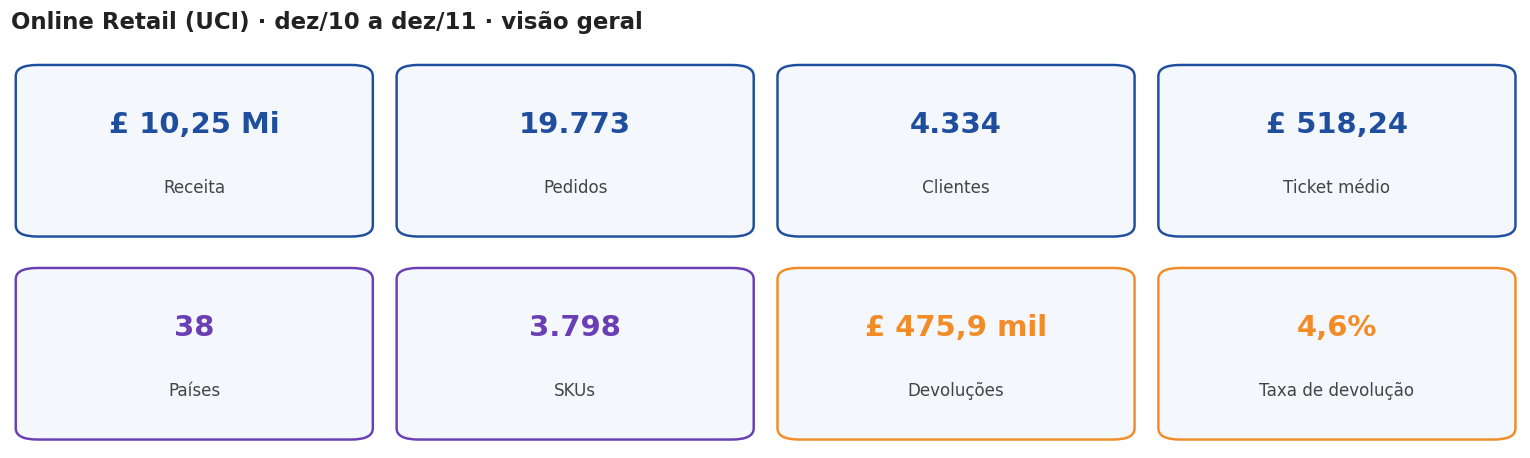

In [6]:
receita        = vendas["Receita"].sum()
pedidos        = vendas["InvoiceNo"].nunique()
clientes       = vendas_cli["CustomerID"].nunique()
ticket         = receita / pedidos
itens_pedido   = vendas.groupby("InvoiceNo")["Quantity"].sum().median()
paises         = vendas["Country"].nunique()
skus           = vendas["StockCode"].nunique()
valor_dev      = -devolucoes["Receita"].sum()
taxa_dev       = valor_dev / receita
rec_sem_cli    = vendas.loc[vendas["CustomerID"].isna(), "Receita"].sum() / receita

kpis = pd.DataFrame({
    "KPI": ["Receita bruta", "Pedidos", "Clientes identificados", "Ticket médio por pedido",
            "Itens por pedido (mediana)", "Países", "SKUs vendidos", "Devoluções (valor)",
            "Taxa de devolução (valor)", "Receita sem cliente identificado"],
    "Valor": [gbp(receita), br(pedidos), br(clientes), gbp(ticket), br(itens_pedido), br(paises), br(skus),
              gbp(valor_dev), pct(taxa_dev), pct(rec_sem_cli)],
})
display(kpis)

# Painel de KPIs (bom para o carrossel do LinkedIn)
cards = [("Receita", gbp(receita)), ("Pedidos", br(pedidos)), ("Clientes", br(clientes)), ("Ticket médio", gbp(ticket)),
         ("Países", br(paises)), ("SKUs", br(skus)), ("Devoluções", gbp(valor_dev)), ("Taxa de devolução", pct(taxa_dev))]
fig, axes = plt.subplots(2, 4, figsize=(14, 4.2))
for ax, (titulo, valor), cor in zip(axes.flat, cards, [AZUL]*4 + [ROXO]*2 + [LARANJA]*2):
    ax.axis("off")
    ax.add_patch(FancyBboxPatch((0.03, 0.06), 0.94, 0.88, boxstyle="round,pad=0.02,rounding_size=0.06",
                                transform=ax.transAxes, fc="#F4F7FC", ec=cor, lw=1.6))
    ax.text(0.5, 0.64, valor, ha="center", va="center", fontsize=19, weight="bold", color=cor, transform=ax.transAxes)
    ax.text(0.5, 0.30, titulo, ha="center", va="center", fontsize=11, color="#444", transform=ax.transAxes)
fig.suptitle("Online Retail (UCI) · dez/10 a dez/11 · visão geral", x=0.01, ha="left", fontsize=15, weight="bold", color="#222")
plt.tight_layout(); salvar(fig, "01_kpis"); plt.show()

## 6. Sazonalidade — receita mensal

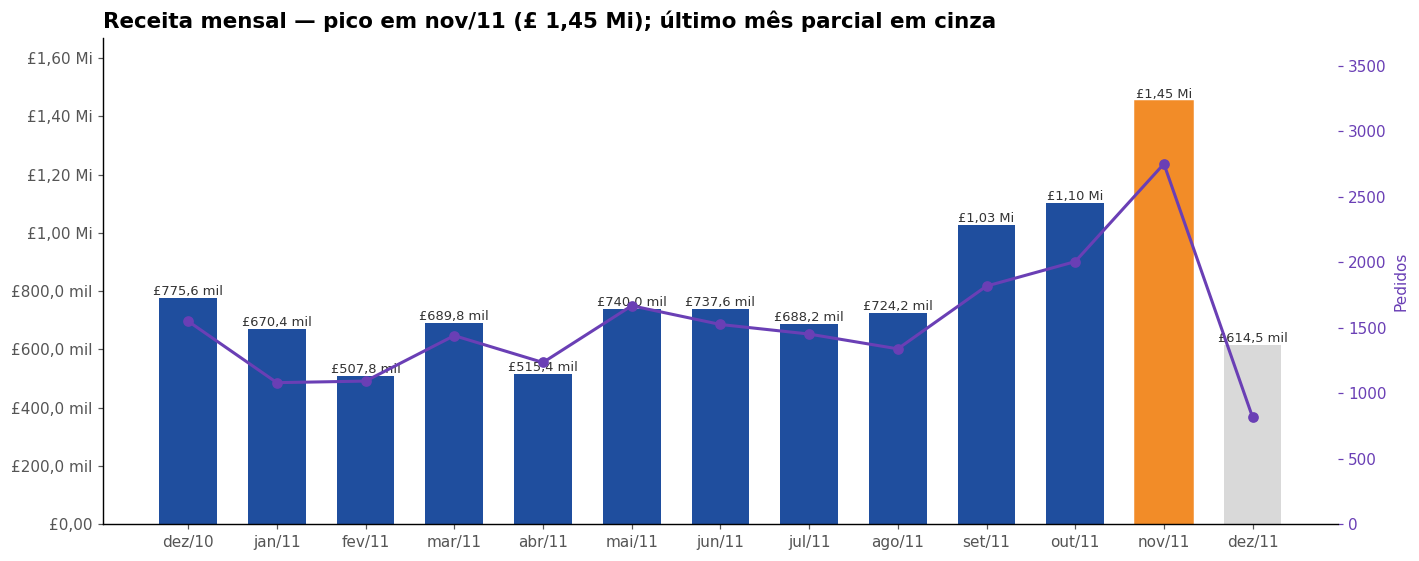

,Receita,Pedidos,Clientes,Ticket,MoM %,Completo
Label,,,,,,
dez/10,"775,638.36",1550,884,500.41,NaN,True
jan/11,"670,380.24",1081,739,620.15,-0.14,True
fev/11,"507,799.87",1093,757,464.59,-0.24,True
mar/11,"689,833.51",1440,973,479.05,0.36,True
abr/11,"515,377.99",1235,853,417.31,-0.25,True
mai/11,"739,953.00",1668,1054,443.62,0.44,True
jun/11,"737,558.98",1525,990,483.65,-0.00,True
jul/11,"688,219.34",1452,946,473.98,-0.07,True
ago/11,"724,216.50",1339,933,540.86,0.05,True


In [7]:
mensal = (vendas.groupby("Mes")
          .agg(Receita=("Receita", "sum"), Pedidos=("InvoiceNo", "nunique"), Clientes=("CustomerID", "nunique"))
          .reset_index())
mensal["Ticket"] = mensal["Receita"] / mensal["Pedidos"]
mensal["MoM %"]  = mensal["Receita"].pct_change()
ultimo_dia = vendas["InvoiceDate"].max()
mensal["Completo"] = ~((mensal["Mes"] == ultimo_dia.to_period("M")) & (ultimo_dia.day < ultimo_dia.days_in_month))
mensal["Label"] = mensal["Mes"].apply(mes_lbl)

fig, ax = plt.subplots(figsize=(13, 5.2))
cores = [AZUL if c else "#D9D9D9" for c in mensal["Completo"]]
bars = ax.bar(mensal["Label"], mensal["Receita"], color=cores, width=0.65)
mes_pico = mensal.loc[mensal.loc[mensal["Completo"], "Receita"].idxmax()]
bars[mensal.index.get_loc(mes_pico.name)].set_color(LARANJA)
for b, v in zip(bars, mensal["Receita"]):
    ax.text(b.get_x() + b.get_width()/2, v, gbp(v).replace("£ ", "£"), ha="center", va="bottom", fontsize=8.5, color="#333")
fmt_eixo_gbp(ax)
ax2 = ax.twinx()
ax2.plot(mensal["Label"], mensal["Pedidos"], color=ROXO, marker="o", lw=2, label="Pedidos")
ax2.set_ylabel("Pedidos", color=ROXO); ax2.spines["top"].set_visible(False); ax2.tick_params(axis="y", colors=ROXO)
ax2.set_ylim(0, mensal["Pedidos"].max() * 1.35)
ax.set_title(f"Receita mensal — pico em {mes_pico['Label']} ({gbp(mes_pico['Receita'])}); último mês parcial em cinza")
ax.set_ylim(0, mensal["Receita"].max() * 1.15)
plt.tight_layout(); salvar(fig, "02_receita_mensal"); plt.show()

display(mensal.drop(columns="Mes").set_index("Label"))

### Sazonalidade semanal e por hora

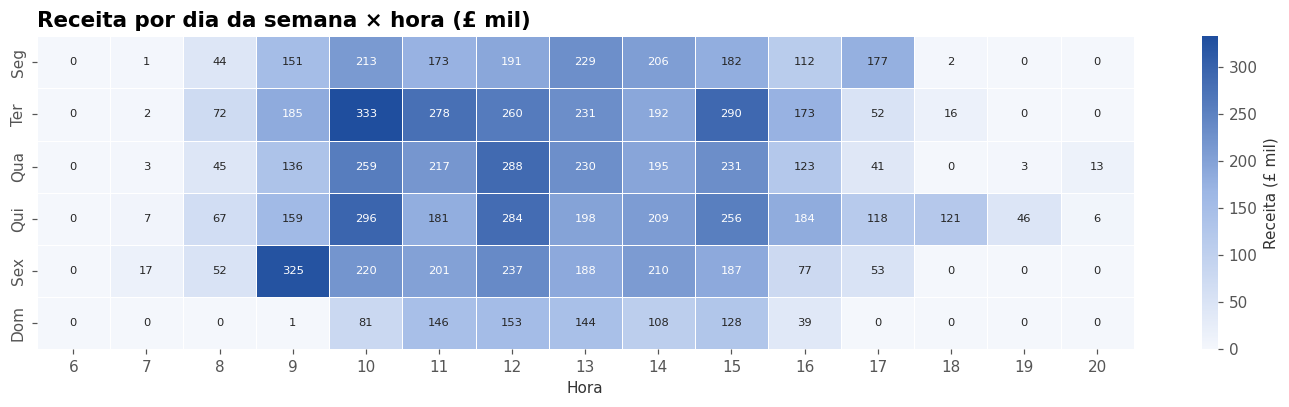

Dia com maior receita: Qui | Hora de pico: 12h | 10h–15h concentra 74,4% da receita
Dias sem vendas na base: ['Sáb']


In [8]:
DIAS = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
heat = vendas.pivot_table(index="DiaSem", columns="Hora", values="Receita", aggfunc="sum").fillna(0)
heat.index = [DIAS[i] for i in heat.index]

fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(heat / 1e3, cmap=CMAP_AZUL, linewidths=0.5, linecolor="white", ax=ax,
            annot=True, fmt=".0f", annot_kws={"size": 7.5}, cbar_kws={"label": "Receita (£ mil)"})
ax.set_title("Receita por dia da semana × hora (£ mil)"); ax.set_xlabel("Hora"); ax.set_ylabel("")
plt.tight_layout(); salvar(fig, "03_heatmap_dia_hora"); plt.show()

dia_top  = heat.sum(axis=1).idxmax()
hora_top = heat.sum(axis=0).idxmax()
janela   = heat.loc[:, [h for h in heat.columns if 10 <= h <= 15]].sum().sum() / heat.sum().sum()
dias_sem_venda = [d for d in DIAS if d not in heat.index]
print(f"Dia com maior receita: {dia_top} | Hora de pico: {hora_top}h | 10h–15h concentra {pct(janela)} da receita")
print(f"Dias sem vendas na base: {dias_sem_venda or 'nenhum'}")

## 7. Países

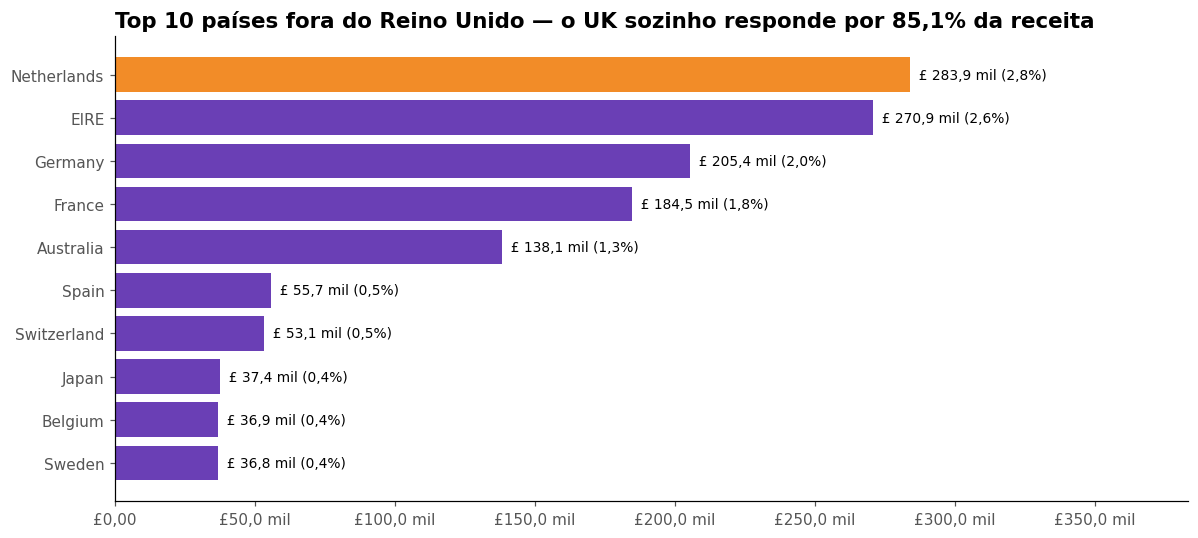

,Receita,Pedidos,Clientes,Share,Ticket
Country,,,,,
United Kingdom,"8,724,443.67",17901,3916,0.85,487.37
Netherlands,"283,889.34",93,9,0.03,"3,052.57"
EIRE,"270,850.86",282,3,0.03,960.46
Germany,"205,381.15",443,94,0.02,463.61
France,"184,493.00",382,87,0.02,482.97
Australia,"138,103.81",56,9,0.01,"2,466.14"
Spain,"55,706.56",88,30,0.01,633.03
Switzerland,"53,065.60",50,21,0.01,"1,061.31"
Japan,"37,416.37",19,8,0.00,"1,969.28"


In [9]:
pais = (vendas.groupby("Country")
        .agg(Receita=("Receita", "sum"), Pedidos=("InvoiceNo", "nunique"), Clientes=("CustomerID", "nunique"))
        .sort_values("Receita", ascending=False))
pais["Share"] = pais["Receita"] / pais["Receita"].sum()
pais["Ticket"] = pais["Receita"] / pais["Pedidos"]
share_uk = pais.loc["United Kingdom", "Share"] if "United Kingdom" in pais.index else 0

top_ext = pais.drop(index="United Kingdom", errors="ignore").head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top_ext.index, top_ext["Receita"], color=[ROXO]*9 + [LARANJA])
for i, (v, s) in enumerate(zip(top_ext["Receita"], top_ext["Share"])):
    ax.text(v, i, f"  {gbp(v)} ({pct(s)})", va="center", fontsize=9)
fmt_eixo_gbp(ax, "x"); ax.set_xlim(0, top_ext["Receita"].max() * 1.35)
ax.set_title(f"Top 10 países fora do Reino Unido — o UK sozinho responde por {pct(share_uk)} da receita")
plt.tight_layout(); salvar(fig, "04_paises"); plt.show()

display(pais.head(15))

## 8. Produtos — curva ABC (Pareto)

,SKUs,Receita,% SKUs,% Receita
Classe,,,,
A,815,"8,196,905.39",0.21,0.80
B,965,"1,537,787.05",0.25,0.15
C,2018,"512,526.88",0.53,0.05


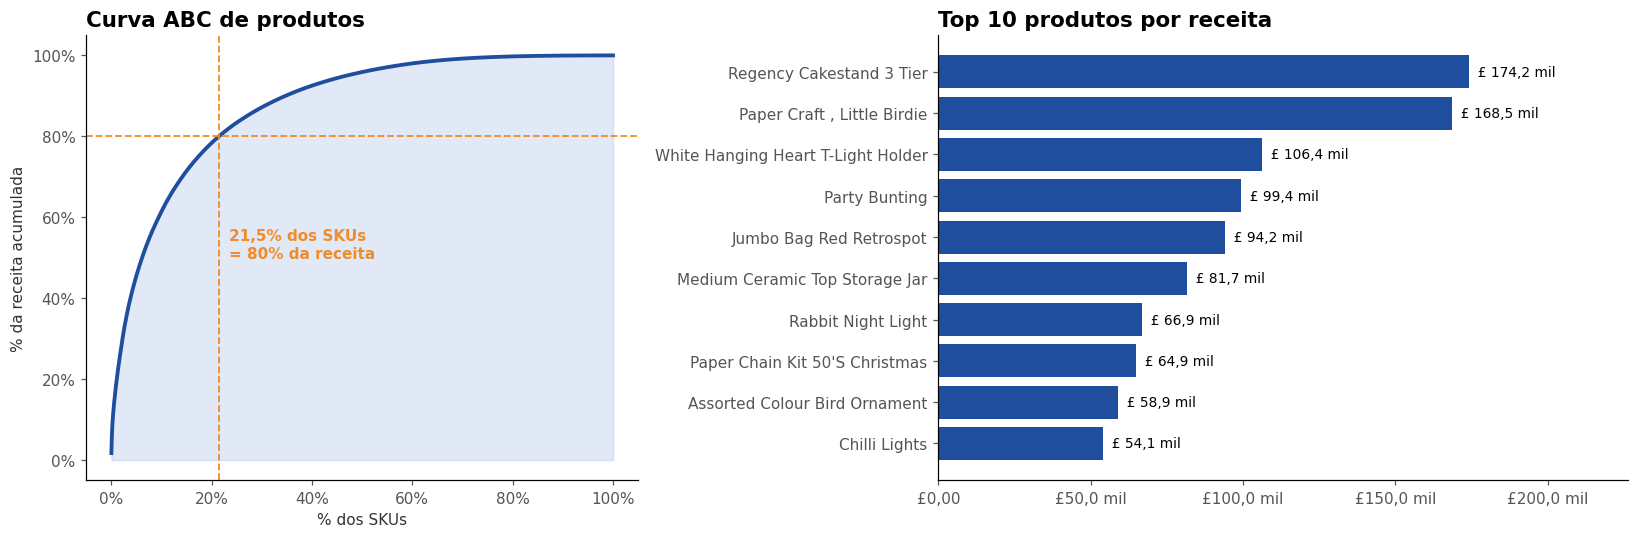

In [10]:
prod = (vendas.groupby("StockCode")
        .agg(Descricao=("Description", "first"), Receita=("Receita", "sum"),
             Quantidade=("Quantity", "sum"), Pedidos=("InvoiceNo", "nunique"))
        .sort_values("Receita", ascending=False))
prod["Share"]  = prod["Receita"] / prod["Receita"].sum()
prod["Acum"]   = prod["Share"].cumsum()
prod["Classe"] = np.select([prod["Acum"] <= 0.80, prod["Acum"] <= 0.95], ["A", "B"], "C")

abc = prod.groupby("Classe").agg(SKUs=("Receita", "size"), Receita=("Receita", "sum"))
abc["% SKUs"] = abc["SKUs"] / abc["SKUs"].sum()
abc["% Receita"] = abc["Receita"] / abc["Receita"].sum()
display(abc)

pct_skus_80 = abc.loc["A", "% SKUs"] if "A" in abc.index else np.nan

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.25]})
x = np.arange(1, len(prod) + 1) / len(prod)
axes[0].plot(x, prod["Acum"], color=AZUL, lw=2.5)
axes[0].fill_between(x, prod["Acum"], color=AZUL_CLARO, alpha=0.3)
axes[0].axhline(0.8, color=LARANJA, ls="--", lw=1.2); axes[0].axvline(pct_skus_80, color=LARANJA, ls="--", lw=1.2)
axes[0].text(pct_skus_80 + 0.02, 0.5, f"{pct(pct_skus_80)} dos SKUs\n= 80% da receita", color=LARANJA, weight="bold")
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set_xlabel("% dos SKUs"); axes[0].set_ylabel("% da receita acumulada"); axes[0].set_title("Curva ABC de produtos")

top10 = prod.head(10).iloc[::-1]
nomes = top10["Descricao"].fillna(top10.index.to_series()).astype(str).str.title().str.slice(0, 38)
axes[1].barh(nomes, top10["Receita"], color=AZUL)
for i, v in enumerate(top10["Receita"]):
    axes[1].text(v, i, f"  {gbp(v)}", va="center", fontsize=9)
fmt_eixo_gbp(axes[1], "x"); axes[1].set_xlim(0, top10["Receita"].max() * 1.3)
axes[1].set_title("Top 10 produtos por receita")
plt.tight_layout(); salvar(fig, "05_produtos_abc"); plt.show()

## 9. Devoluções e cancelamentos

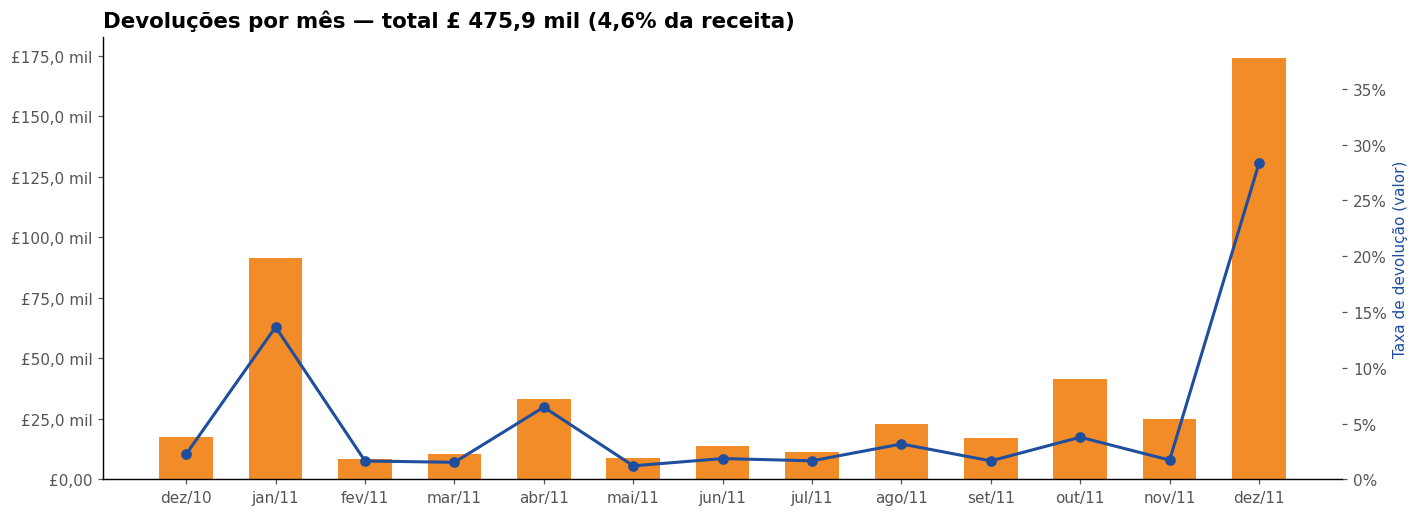

Top 10 produtos por valor devolvido (% > 100% indica devolução de compra anterior ao período da base):


,Descricao,ValorDevolvido,QtdDevolvida,Notas,Receita,% sobre venda
StockCode,,,,,,
23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995,1,"168,469.60",1.00
23166,MEDIUM CERAMIC TOP STORAGE JAR,"77,479.64",74494,10,"81,700.92",0.95
22423,REGENCY CAKESTAND 3 TIER,"9,697.05",855,180,"174,156.54",0.06
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"6,624.30",2578,42,"106,415.23",0.06
21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,"6,591.42",3150,3,"18,056.28",0.37
23113,PANTRY CHOPPING BOARD,"4,803.06",946,6,"5,868.50",0.82
48185,DOORMAT FAIRY CAKE,"4,554.90",674,3,"23,872.91",0.19
21175,GIN + TONIC DIET METAL SIGN,"3,775.33",2030,7,"27,029.97",0.14
47566B,TEA TIME PARTY BUNTING,"3,692.95",1424,7,"12,926.42",0.29


Países com maior taxa de devolução (receita > £ 20 mil):


,Devolucao,Receita,Taxa
Country,,,
Spain,"3,959.91","55,706.56",0.07
Japan,"1,996.58","37,416.37",0.05
United Kingdom,"443,053.31","8,724,443.67",0.05
Sweden,"1,662.42","36,828.83",0.05
EIRE,"11,470.84","270,850.86",0.04
Germany,"4,761.49","205,381.15",0.02
France,"2,416.40","184,493.00",0.01
Switzerland,582.55,"53,065.60",0.01
Australia,"1,181.31","138,103.81",0.01


In [11]:
dev_mes = devolucoes.groupby("Mes")["Receita"].sum().mul(-1).rename("Devolucao")
dev_mes = mensal.set_index("Mes")[["Receita", "Label"]].join(dev_mes).fillna({"Devolucao": 0})
dev_mes["Taxa"] = dev_mes["Devolucao"] / dev_mes["Receita"]

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.bar(dev_mes["Label"], dev_mes["Devolucao"], color=LARANJA, width=0.6)
fmt_eixo_gbp(ax)
ax2 = ax.twinx()
ax2.plot(dev_mes["Label"], dev_mes["Taxa"], color=AZUL, marker="o", lw=2)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax2.spines["top"].set_visible(False)
ax2.set_ylim(0, dev_mes["Taxa"].max() * 1.4)
ax2.set_ylabel("Taxa de devolução (valor)", color=AZUL)
ax.set_title(f"Devoluções por mês — total {gbp(valor_dev)} ({pct(taxa_dev)} da receita)")
plt.tight_layout(); salvar(fig, "06_devolucoes_mes"); plt.show()

dev_prod = (devolucoes.groupby("StockCode")
            .agg(Descricao=("Description", "first"), ValorDevolvido=("Receita", lambda s: -s.sum()),
                 QtdDevolvida=("Quantity", lambda s: -s.sum()), Notas=("InvoiceNo", "nunique"))
            .join(prod[["Receita"]]).sort_values("ValorDevolvido", ascending=False))
dev_prod["% sobre venda"] = dev_prod["ValorDevolvido"] / dev_prod["Receita"]
print("Top 10 produtos por valor devolvido (% > 100% indica devolução de compra anterior ao período da base):")
display(dev_prod.head(10))

dev_pais = (devolucoes.groupby("Country")["Receita"].sum().mul(-1).rename("Devolucao").to_frame()
            .join(pais[["Receita"]]))
dev_pais["Taxa"] = dev_pais["Devolucao"] / dev_pais["Receita"]
print("Países com maior taxa de devolução (receita > £ 20 mil):")
display(dev_pais[dev_pais["Receita"] > 20000].sort_values("Taxa", ascending=False).head(10))

## 10. Concentração de vendas por cliente

,Faixa de clientes,Clientes,% da receita
0,Top 1%,43,"32,0%"
1,Top 5%,216,"50,4%"
2,Top 10%,433,"61,4%"
3,Top 20%,866,"74,6%"


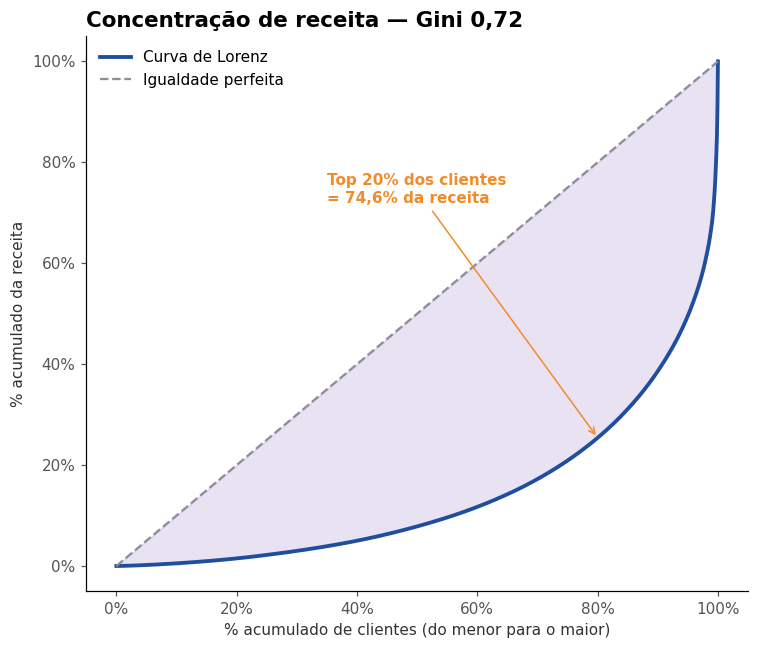

In [12]:
cli = vendas_cli.groupby("CustomerID")["Receita"].sum().sort_values(ascending=False)
n = len(cli)
conc = pd.DataFrame({
    "Faixa de clientes": ["Top 1%", "Top 5%", "Top 10%", "Top 20%"],
    "Clientes": [max(1, int(n*p)) for p in (0.01, 0.05, 0.10, 0.20)],
})
conc["% da receita"] = [cli.head(k).sum() / cli.sum() for k in conc["Clientes"]]
display(conc.assign(**{"% da receita": conc["% da receita"].map(pct)}))

def gini(v):
    v = np.sort(np.asarray(v, dtype=float)); k = len(v)
    return (2 * np.sum(np.arange(1, k+1) * v) / (k * v.sum())) - (k + 1) / k
g = gini(cli.values)
top10_share = conc.loc[2, "% da receita"]
top20_share = conc.loc[3, "% da receita"]

lor = np.insert(np.cumsum(np.sort(cli.values)) / cli.sum(), 0, 0)
xs = np.linspace(0, 1, len(lor))
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(xs, lor, color=AZUL, lw=2.5, label="Curva de Lorenz")
ax.plot([0, 1], [0, 1], color=CINZA, ls="--", label="Igualdade perfeita")
ax.fill_between(xs, xs, lor, color=ROXO, alpha=0.15)
ax.annotate(f"Top 20% dos clientes\n= {pct(top20_share)} da receita", xy=(0.8, 1 - top20_share),
            xytext=(0.35, 0.72), color=LARANJA, weight="bold", arrowprops=dict(arrowstyle="->", color=LARANJA))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("% acumulado de clientes (do menor para o maior)"); ax.set_ylabel("% acumulado da receita")
ax.set_title(f"Concentração de receita — Gini {br(g, 2)}"); ax.legend(loc="upper left", frameon=False)
plt.tight_layout(); salvar(fig, "07_concentracao_clientes"); plt.show()

## 11. Segmentação RFM
- **R**ecência: dias desde a última compra · **F**requência: nº de pedidos · **M**onetário: receita total
- Notas de 1 a 5 por quintil; segmento definido pela combinação R × F.

,Clientes,Receita,Recencia_media,Freq_media,Ticket_cliente,% Clientes,% Receita
Segmento,,,,,,,
Campeões,633,"4,285,180.33",5.90,12.34,"6,769.64",0.15,0.49
Leais,817,"2,272,785.14",33.05,6.43,"2,781.87",0.19,0.26
Em risco,591,"634,001.01",152.51,2.86,"1,072.76",0.14,0.07
Hibernando,1078,"515,889.91",217.00,1.10,478.56,0.25,0.06
Potenciais leais,477,"489,183.04",16.65,2.00,"1,025.54",0.11,0.06
Não pode perder,65,"176,716.94",132.83,8.26,"2,718.72",0.01,0.02
Precisam de atenção,190,"158,157.52",51.19,2.31,832.41,0.04,0.02
Prestes a dormir,346,"156,442.31",52.60,1.14,452.15,0.08,0.02
Promissores,96,"33,640.90",22.98,1.00,350.43,0.02,0.00


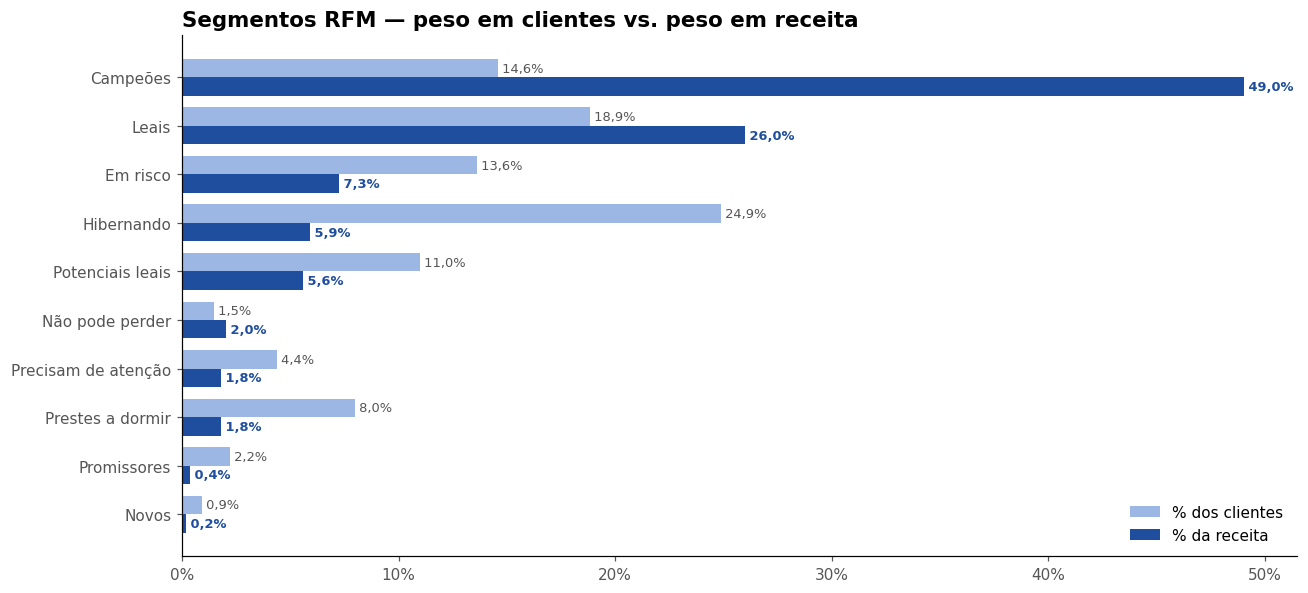

In [13]:
snapshot = vendas_cli["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = vendas_cli.groupby("CustomerID").agg(
    Recencia=("InvoiceDate", lambda s: (snapshot - s.max()).days),
    Frequencia=("InvoiceNo", "nunique"),
    Monetario=("Receita", "sum"),
)
rfm["R"] = pd.qcut(rfm["Recencia"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequencia"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetario"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

SEGMENTOS = [
    (r"5[4-5]",     "Campeões"),
    (r"[3-4][4-5]", "Leais"),
    (r"[4-5][2-3]", "Potenciais leais"),
    (r"51",         "Novos"),
    (r"41",         "Promissores"),
    (r"33",         "Precisam de atenção"),
    (r"3[1-2]",     "Prestes a dormir"),
    (r"[1-2]5",     "Não pode perder"),
    (r"[1-2][3-4]", "Em risco"),
    (r"[1-2][1-2]", "Hibernando"),
]
def segmentar(rf):
    for padrao, nome in SEGMENTOS:
        if re.fullmatch(padrao, rf): return nome
    return "Outros"
rfm["Segmento"] = (rfm["R"].astype(str) + rfm["F"].astype(str)).map(segmentar)

seg = rfm.groupby("Segmento").agg(Clientes=("Monetario", "size"), Receita=("Monetario", "sum"),
                                  Recencia_media=("Recencia", "mean"), Freq_media=("Frequencia", "mean"),
                                  Ticket_cliente=("Monetario", "mean"))
seg["% Clientes"] = seg["Clientes"] / seg["Clientes"].sum()
seg["% Receita"]  = seg["Receita"] / seg["Receita"].sum()
seg = seg.sort_values("Receita", ascending=False)
display(seg)

fig, ax = plt.subplots(figsize=(12, 5.5))
s = seg.iloc[::-1]; y = np.arange(len(s)); h = 0.38
ax.barh(y + h/2, s["% Clientes"], h, color=AZUL_CLARO, label="% dos clientes")
ax.barh(y - h/2, s["% Receita"], h, color=AZUL, label="% da receita")
for i, (c, r) in enumerate(zip(s["% Clientes"], s["% Receita"])):
    ax.text(c, i + h/2, f" {pct(c)}", va="center", fontsize=8.5, color="#555")
    ax.text(r, i - h/2, f" {pct(r)}", va="center", fontsize=8.5, color=AZUL, weight="bold")
ax.set_yticks(y); ax.set_yticklabels(s.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.legend(frameon=False, loc="lower right")
ax.set_title("Segmentos RFM — peso em clientes vs. peso em receita")
plt.tight_layout(); salvar(fig, "08_rfm_segmentos"); plt.show()

## 12. Coortes de retenção

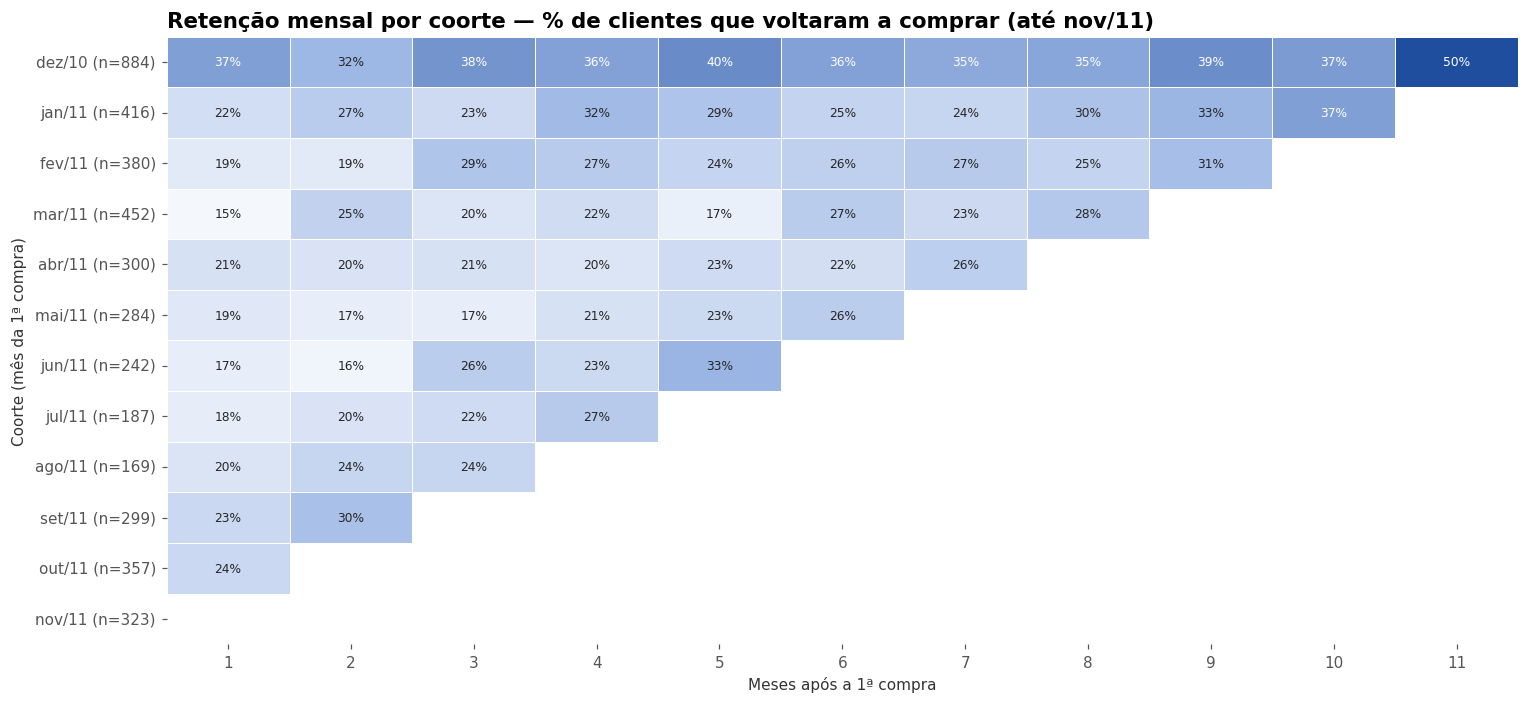

Retenção média no mês 1: 21,3%
Coorte dez/10: 37,9% de retenção média mensal ao longo do ano
Clientes com 2+ pedidos: 65,3% da base e 92,8% da receita identificada


In [14]:
# Remove o mês parcial (dez/11 vai só até dia 9) para não distorcer a última diagonal
meses_parciais = mensal.loc[~mensal["Completo"], "Mes"].tolist()
c = vendas_cli.loc[~vendas_cli["Mes"].isin(meses_parciais), ["CustomerID", "InvoiceDate"]].copy()
c["MesIdx"] = c["InvoiceDate"].dt.year * 12 + c["InvoiceDate"].dt.month - 1
c["CoorteIdx"] = c.groupby("CustomerID")["MesIdx"].transform("min")
c["Idade"] = c["MesIdx"] - c["CoorteIdx"]
c["Coorte"] = c["InvoiceDate"].dt.to_period("M").where(c["Idade"] == 0)
c["Coorte"] = c.groupby("CustomerID")["Coorte"].transform("first")

matriz = c.groupby(["Coorte", "Idade"])["CustomerID"].nunique().unstack()
tamanho = matriz[0]
retencao = matriz.div(tamanho, axis=0)
retencao.index = [mes_lbl(p) for p in retencao.index]

fig, ax = plt.subplots(figsize=(14, 6.5))
sns.heatmap(retencao.iloc[:, 1:], cmap=CMAP_AZUL, annot=True, fmt=".0%", annot_kws={"size": 8},
            linewidths=0.5, linecolor="white", cbar=False, ax=ax)
ax.set_yticklabels([f"{l} (n={br(t)})" for l, t in zip(retencao.index, tamanho)], rotation=0)
ax.set_xlabel("Meses após a 1ª compra"); ax.set_ylabel("Coorte (mês da 1ª compra)")
ax.set_title("Retenção mensal por coorte — % de clientes que voltaram a comprar (até nov/11)")
plt.tight_layout(); salvar(fig, "09_coortes"); plt.show()

ret_m1_media = retencao[1].mean() if 1 in retencao.columns else np.nan
ret_dez10 = retencao.iloc[0].dropna()
print(f"Retenção média no mês 1: {pct(ret_m1_media)}")
print(f"Coorte {retencao.index[0]}: {pct(ret_dez10.iloc[1:].mean())} de retenção média mensal ao longo do ano")
recorrentes = (rfm["Frequencia"] > 1).mean()
rec_recorrentes = rfm.loc[rfm["Frequencia"] > 1, "Monetario"].sum() / rfm["Monetario"].sum()
print(f"Clientes com 2+ pedidos: {pct(recorrentes)} da base e {pct(rec_recorrentes)} da receita identificada")

## 13. Insights executivos

In [15]:
completos = mensal[mensal["Completo"]].copy()
m2011 = completos[completos["Mes"].dt.year == 2011]
ini, fim = m2011.iloc[0], m2011.loc[m2011["Receita"].idxmax()]
cresc = fim["Receita"] / ini["Receita"] - 1
delta = fim["Receita"] - ini["Receita"]
q4 = completos[completos["Mes"].dt.month.isin([9, 10, 11]) & (completos["Mes"].dt.year == 2011)]["Receita"].sum()
share_q4 = q4 / completos[completos["Mes"].dt.year == 2011]["Receita"].sum()

seg_top = seg.index[0]
campeoes = seg.loc["Campeões"] if "Campeões" in seg.index else None
risco = seg.loc[[s for s in ["Em risco", "Não pode perder"] if s in seg.index]]

insights = [
    f"Receita de {gbp(receita)} em {br(pedidos)} pedidos, ticket médio de {gbp(ticket)} e {br(clientes)} clientes identificados em {br(paises)} países.",
    f"Crescimento de (+{pct(cresc, 0)}, +{gbp(delta)}), saindo de {gbp(ini['Receita'])} em {ini['Label']} para {gbp(fim['Receita'])} em {fim['Label']} — o pico do ano.",
    f"Set–nov/11 concentram {pct(share_q4)} da receita de 2011: o negócio é fortemente sazonal (compras para o Natal).",
    f"Vendas acontecem em horário comercial: pico às {hora_top}h e a janela 10h–15h responde por {pct(janela)} da receita.",
    f"Dependência do mercado interno: o Reino Unido responde por {pct(share_uk)} da receita.",
    f"Curva ABC: {pct(pct_skus_80)} dos SKUs geram 80% da receita.",
    f"Top 10% dos clientes concentram {pct(top10_share)} da receita (Gini {br(g, 2)}).",
    f"Devoluções somam {gbp(valor_dev)} ({pct(taxa_dev)} da receita).",
]
if campeoes is not None:
    insights.append(f"Campeões são {pct(campeoes['% Clientes'])} da base e trazem {pct(campeoes['% Receita'])} da receita.")
if len(risco):
    insights.append(f"Em risco / Não pode perder: {br(risco['Clientes'].sum())} clientes que já somaram {gbp(risco['Receita'].sum())} — prioridade de reativação.")
insights.append(f"Só {pct(ret_m1_media)} dos novos clientes voltam no mês seguinte, em média — retenção é a maior alavanca.")

recomendacoes = [
    "Antecipar estoque e campanhas para set–nov, com foco nos SKUs classe A.",
    "Programa de relacionamento para Campeões/Leais (atacadistas) e régua de reativação para Em risco.",
    "Ação de 2ª compra nos primeiros 30 dias para elevar a retenção no mês 1.",
    "Investigar os produtos e países com maior taxa de devolução (qualidade, descrição, logística).",
    "Diversificar receita fora do UK, começando pelos mercados com maior ticket.",
]

print("INSIGHTS")
for i in insights: print(" •", i)
print("\nRECOMENDAÇÕES")
for r in recomendacoes: print(" •", r)

INSIGHTS
 • Receita de £ 10,25 Mi em 19.773 pedidos, ticket médio de £ 518,24 e 4.334 clientes identificados em 38 países.
 • Crescimento de (+117%, +£ 781,7 mil), saindo de £ 670,4 mil em jan/11 para £ 1,45 Mi em nov/11 — o pico do ano.
 • Set–nov/11 concentram 40,5% da receita de 2011: o negócio é fortemente sazonal (compras para o Natal).
 • Vendas acontecem em horário comercial: pico às 12h e a janela 10h–15h responde por 74,4% da receita.
 • Dependência do mercado interno: o Reino Unido responde por 85,1% da receita.
 • Curva ABC: 21,5% dos SKUs geram 80% da receita.
 • Top 10% dos clientes concentram 61,4% da receita (Gini 0,72).
 • Devoluções somam £ 475,9 mil (4,6% da receita).
 • Campeões são 14,6% da base e trazem 49,0% da receita.
 • Em risco / Não pode perder: 656 clientes que já somaram £ 810,7 mil — prioridade de reativação.
 • Só 21,3% dos novos clientes voltam no mês seguinte, em média — retenção é a maior alavanca.

RECOMENDAÇÕES
 • Antecipar estoque e campanhas para s

## 14. Exportação (Excel + gráficos + post do LinkedIn)

In [16]:
arq_xlsx = f"{OUT}/online_retail_analise.xlsx"
with pd.ExcelWriter(arq_xlsx, engine="openpyxl") as w:
    pd.DataFrame({"Insights": insights}).to_excel(w, sheet_name="Insights", index=False)
    kpis.to_excel(w, sheet_name="KPIs", index=False)
    auditoria.to_excel(w, sheet_name="Qualidade", index=False)
    funil_df.to_excel(w, sheet_name="Limpeza", index=False)
    mensal.drop(columns="Mes").to_excel(w, sheet_name="Mensal", index=False)
    pais.to_excel(w, sheet_name="Paises")
    prod.to_excel(w, sheet_name="Produtos_ABC")
    dev_prod.head(200).to_excel(w, sheet_name="Devolucoes_Produto")
    seg.to_excel(w, sheet_name="RFM_Segmentos")
    rfm.to_excel(w, sheet_name="RFM_Clientes")
    retencao.to_excel(w, sheet_name="Coortes")

post = f'''📊 Novo projeto de análise de dados: Online Retail (UCI)

Peguei ~{br(len(raw)/1000)} mil transações de um e-commerce do Reino Unido e respondi perguntas de negócio com Python.

O que os dados mostraram:
🔹 {gbp(receita)} de receita em {br(pedidos)} pedidos (ticket médio de {gbp(ticket)})
🔹 Sazonalidade forte: set–nov concentram {pct(share_q4)} da receita de 2011
🔹 {pct(pct_skus_80)} dos produtos geram 80% do faturamento
🔹 Top 10% dos clientes = {pct(top10_share)} da receita
🔹 Só {pct(ret_m1_media)} dos novos clientes voltam no mês seguinte
🔹 Devoluções de {gbp(valor_dev)} ({pct(taxa_dev)} da receita)

Etapas: auditoria de qualidade → limpeza documentada → KPIs → sazonalidade → curva ABC → devoluções → concentração (Lorenz/Gini) → RFM → coortes.

Stack: Python, pandas, matplotlib, seaborn · Google Colab

Base: Chen, D. (2015). Online Retail. UCI Machine Learning Repository (CC BY 4.0).

#dataanalytics #python #pandas #analisededados #businessintelligence #rfm
'''
with open(f"{OUT}/post_linkedin.txt", "w", encoding="utf-8") as f:
    f.write(post)
print(post)

shutil.make_archive("projeto_online_retail", "zip", OUT)
print("Arquivos gerados:", sorted(os.listdir(OUT)))
try:
    from google.colab import files
    files.download("projeto_online_retail.zip")
except ImportError:
    print("Fora do Colab: o zip está em ./projeto_online_retail.zip")

📊 Novo projeto de análise de dados: Online Retail (UCI)

Peguei ~542 mil transações de um e-commerce do Reino Unido e respondi perguntas de negócio com Python.

O que os dados mostraram:
🔹 £ 10,25 Mi de receita em 19.773 pedidos (ticket médio de £ 518,24)
🔹 Sazonalidade forte: set–nov concentram 40,5% da receita de 2011
🔹 21,5% dos produtos geram 80% do faturamento
🔹 Top 10% dos clientes = 61,4% da receita
🔹 Só 21,3% dos novos clientes voltam no mês seguinte
🔹 Devoluções de £ 475,9 mil (4,6% da receita)

Etapas: auditoria de qualidade → limpeza documentada → KPIs → sazonalidade → curva ABC → devoluções → concentração (Lorenz/Gini) → RFM → coortes.

Stack: Python, pandas, matplotlib, seaborn · Google Colab

Base: Chen, D. (2015). Online Retail. UCI Machine Learning Repository (CC BY 4.0).

#dataanalytics #python #pandas #analisededados #businessintelligence #rfm

Arquivos gerados: ['01_kpis.png', '02_receita_mensal.png', '03_heatmap_dia_hora.png', '04_paises.png', '05_produtos_abc.png',

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Conclusão
Os gráficos em `outputs/` (PNG 200 dpi) estão prontos para um carrossel no LinkedIn, e o Excel traz todas as tabelas do estudo.

**Próximos passos possíveis:** previsão de demanda para o Q4, CLV (valor do cliente no tempo) e análise de cesta (produtos comprados juntos).